# Phase 3: Feature Extraction & Pattern Recognition

**Goal:** describe each soft-tissue region with a feature vector $\mathbf{x} = [f_1, \dots, f_d]^T$ and classify it as **Healthy tissue (0)** or **Tumor (1)** with a *classical* classifier (no pre-trained or deep-learning models).

| Task | What is done here |
|---|---|
| 1 | Build the ROI dataset, extract 15 shape, GLCM and first-order features |
| 2 | Normalise, then train SVM, k-NN and Random Forest with a **70/30 patient split** and **5-fold cross-validation** on the 70 % |
| 3 | Confusion matrix, accuracy, sensitivity, specificity, precision, F1; error analysis; end-to-end test on raw slices |

Code lives in `../source/features.py`, `../source/classification.py` and `../source/metrics.py`.

In [1]:
import sys, os
sys.path.append("../source")          # the modules live in ../source
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import utilities as util
import enhancement as enh

import segmentation as S
import features as feat
import classification as C
import metrics as M
import joblib

def crop_to_body(img, body, margin=8):
    ys, xs = np.where(body)
    return img[max(ys.min() - margin, 0):ys.max() + margin, max(xs.min() - margin, 0):xs.max() + margin]

DATA_DIR = "../data/slices"           # extracted .npz slices (patient_<N>.npz)
FIG_DIR = "../figures"                # figures for the report are saved here
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams["figure.dpi"] = 90
plt.rcParams["figure.max_open_warning"] = 0

In [2]:
SEED = 42
train_p, test_p = util.split_patients(util.list_patients(DATA_DIR), 0.30, SEED)
print("training patients (%d): %s" % (len(train_p), train_p))
print("test patients     (%d): %s" % (len(test_p), test_p))

training patients (21): [0, 1, 2, 3, 4, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 24, 28, 29]
test patients     (9): [5, 7, 17, 22, 23, 25, 26, 27, 30]


## Task 1a: The ROI dataset

A region of interest needs both a *healthy* and a *tumor* class, but healthy tissue has no natural outline. Three kinds of regions are therefore collected from every slice that shows enough liver (>= 3000 px):

| kind | what it is | class |
|---|---|---|
| **tumor** | each connected component of the ground-truth tumor mask | 1 |
| **control** | a copy of a tumor's exact **shape and size**, moved to tumor-free liver | 0 |
| **fp_candidate** | a dark blob proposed by the Phase 2 lesion detector (relaxed settings) that is *not* a tumor: vessels, fissures, noise | 0 |

Controls make size and shape identical in both classes, so the classifier cannot succeed on geometry alone. The false-positive candidates are the realistic confusers that a CAD system must reject.

In [3]:
Xtr, ytr, gtr, mtr = C.build_roi_dataset(DATA_DIR, train_p, SEED)
Xte, yte, gte, mte = C.build_roi_dataset(DATA_DIR, test_p, SEED)
kinds = pd.DataFrame({"split": ["train"] * len(mtr) + ["test"] * len(mte), "kind": [m[2] for m in mtr + mte], "class": np.r_[ytr, yte]})
tab = kinds.groupby(["split", "kind"]).size().unstack(0)[["train", "test"]]
tab.loc["TOTAL"] = tab.sum()
print("feature matrix: train", Xtr.shape, " test", Xte.shape)
tab

feature matrix: train (597, 15)  test (239, 15)


split,train,test
kind,,
control,157,62
fp_candidate,273,114
tumor,167,63
TOTAL,597,239


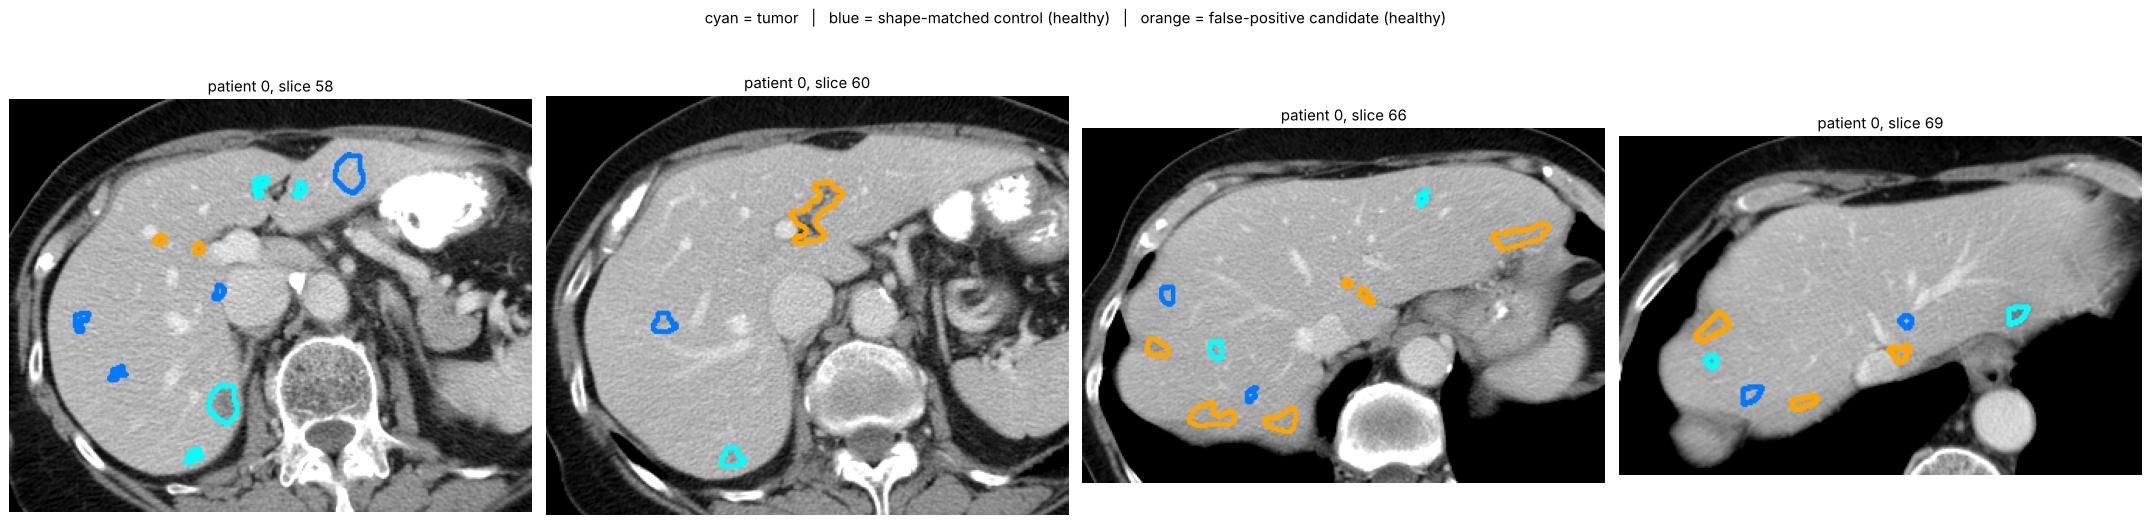

In [4]:
# a few example slices with the three kinds of ROI
rng = np.random.default_rng(0)
COL = {"tumor": (0, 255, 255), "control": (0, 120, 255), "fp_candidate": (255, 165, 0)}
examples = []
for pid, sl, hu_i, m_i in util.iter_slices(DATA_DIR, train_p):
    if (m_i >= 1).sum() < C.MIN_LIVER_PX: continue
    g = util.hu_to_gray(hu_i); rois = C.slice_rois(g, m_i, rng)
    if {"tumor", "control", "fp_candidate"} <= {k for _, _, k in rois}:
        examples.append((pid, sl, hu_i, g, m_i, rois))
    if len(examples) == 4: break

fig, ax = plt.subplots(1, 4, figsize=(24, 6.5))
for a, (pid, sl, hu_i, g, m_i, rois) in zip(ax, examples):
    layers = [(r, COL[k]) for r, _, k in rois]
    ys, xs = np.where(m_i >= 1)
    img = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)
    for r, col in layers:
        cs, _ = cv2.findContours(r.astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE); cv2.drawContours(img, cs, -1, col, 2)
    a.imshow(img[max(ys.min() - 25, 0):ys.max() + 25, max(xs.min() - 25, 0):xs.max() + 25]); a.axis("off"); a.set_title("patient %d, slice %d" % (pid, sl))
fig.suptitle("cyan = tumor   |   blue = shape-matched control (healthy)   |   orange = false-positive candidate (healthy)", y=0.98)
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_roi_examples.png", dpi=90); plt.show()

## Task 1b: Feature extraction (15 features per ROI)

| group | features | meaning |
|---|---|---|
| **Shape (6)** | area, perimeter-to-area, circularity $4\pi A/P^2$, compactness $P^2/4\pi A$, eccentricity, solidity $A/A_{hull}$ | size and outline regularity |
| **GLCM texture (5)** | energy $\sum P^2$, contrast $\sum (i-j)^2 P$, homogeneity $\sum P/(1+(i-j)^2)$, correlation, entropy $-\sum P\log_2 P$ | spatial arrangement of gray levels; 4 angles (0, 45, 90, 135 deg), distance 1, 32 gray levels, averaged over the angles |
| **First-order (4)** | mean HU, variance, skewness, kurtosis | intensity distribution (raw HU, no windowing) |

The GLCM of an ROI only counts pixel pairs that are *both inside* the ROI.

In [5]:
pid, sl, hu_i, gw, m_i, rois = examples[0]
pick = {k: r for r, _, k in rois}                       # one ROI of each kind from the first example slice
rows = {k: feat.extract_features(hu_i, gw, pick[k]) for k in ("tumor", "control", "fp_candidate")}
pd.DataFrame(rows, index=feat.FEATURE_NAMES).round(3)

,tumor,control,fp_candidate
area,54.000,54.000,36.000
perimeter_to_area,0.754,0.754,0.569
circularity,0.409,0.409,1.000
compactness,2.444,2.444,1.000
eccentricity,0.808,0.808,0.566
solidity,0.659,0.659,0.900
glcm_energy,0.087,0.069,0.045
glcm_contrast,1.862,2.535,5.605
glcm_homogeneity,0.519,0.510,0.397
glcm_correlation,0.144,0.213,0.054


energy  contrast  homogeneity  correlation  entropy
ROI          angle                                                       
tumor        0 deg     0.081     0.975        0.662        0.621    3.952
             45 deg    0.092     2.250        0.438       -0.108    3.807
             90 deg    0.087     1.816        0.503        0.109    3.859
             135 deg   0.085     2.406        0.472       -0.046    3.970
control      0 deg     0.078     0.775        0.702        0.786    4.034
             45 deg    0.081     3.500        0.483       -0.080    3.999
             90 deg    0.062     2.895        0.405        0.065    4.257
             135 deg   0.057     2.969        0.449        0.080    4.352
fp_candidate 0 deg     0.053     2.286        0.538        0.655    4.473
             45 deg    0.041     5.840        0.356       -0.062    4.703
             90 deg    0.043     6.367        0.372       -0.092    4.740
             135 deg   0.044     7.926        0.324       -0.286    4.741

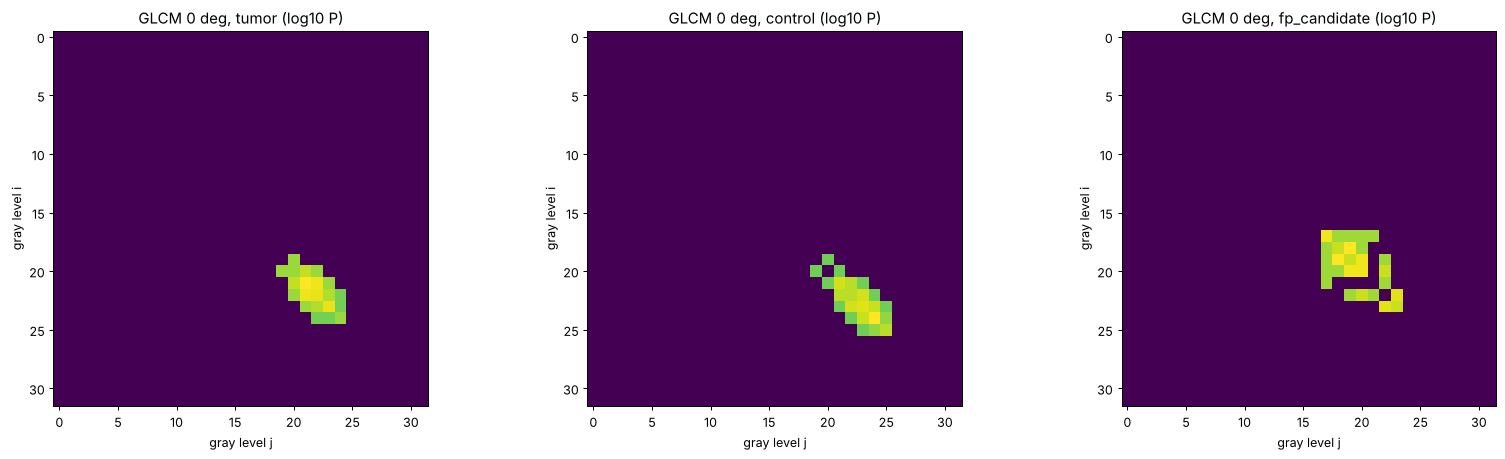

In [6]:
# GLCM per angle (report table) and the co-occurrence matrices themselves (angle 0 deg, log scale)
per_angle = pd.concat({k: pd.DataFrame(feat.glcm_features_per_angle(gw, pick[k]), index=["%d deg" % a for a in feat.GLCM_ANGLES], columns=[n.replace("glcm_", "") for n in feat.GLCM_NAMES]) for k in pick}, names=["ROI", "angle"])
display(per_angle.round(3))
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2))
for a, k in zip(ax, pick):
    P = feat.roi_glcm(gw, pick[k])[:, :, 0]
    a.imshow(np.log10(P + 1e-6), cmap="viridis"); a.set_title("GLCM 0 deg, %s (log10 P)" % k); a.set_xlabel("gray level j"); a.set_ylabel("gray level i")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_glcm_matrices.png", dpi=100); plt.show()

## Feature analysis (training set only)

A one-way ANOVA F-test per feature between healthy and tumor ROIs shows which features carry class information. Features of the three ROI kinds can differ, so the table is followed by boxplots of the most discriminative features and a correlation matrix (redundant features).

In [7]:
ft = pd.DataFrame(C.feature_table(Xtr, ytr), columns=["feature", "healthy mean", "healthy std", "tumor mean", "tumor std", "F", "p"]).set_index("feature")
ft = ft.sort_values("F", ascending=False)
ft.round(3).to_csv(FIG_DIR + "/p3_feature_table.csv")
ft.style.format({"healthy mean": "{:.3f}", "healthy std": "{:.3f}", "tumor mean": "{:.3f}", "tumor std": "{:.3f}", "F": "{:.1f}", "p": "{:.2g}"})

,healthy mean,healthy std,tumor mean,tumor std,F,p
feature,,,,,,
perimeter_to_area,0.443,0.156,0.348,0.173,41.7,2.2e-10
glcm_correlation,0.253,0.158,0.341,0.149,38.8,9e-10
mean_hu,74.699,26.453,61.634,23.789,30.9,4.1e-08
glcm_entropy,5.184,0.872,5.612,0.813,30.0,6.2e-08
eccentricity,0.748,0.169,0.664,0.175,29.5,8.3e-08
area,185.958,373.126,542.731,1311.756,26.2,4.1e-07
glcm_energy,0.042,0.030,0.031,0.020,18.7,1.8e-05
solidity,0.844,0.090,0.878,0.080,18.1,2.4e-05
variance_hu,572.632,434.962,668.287,509.216,5.3,0.022


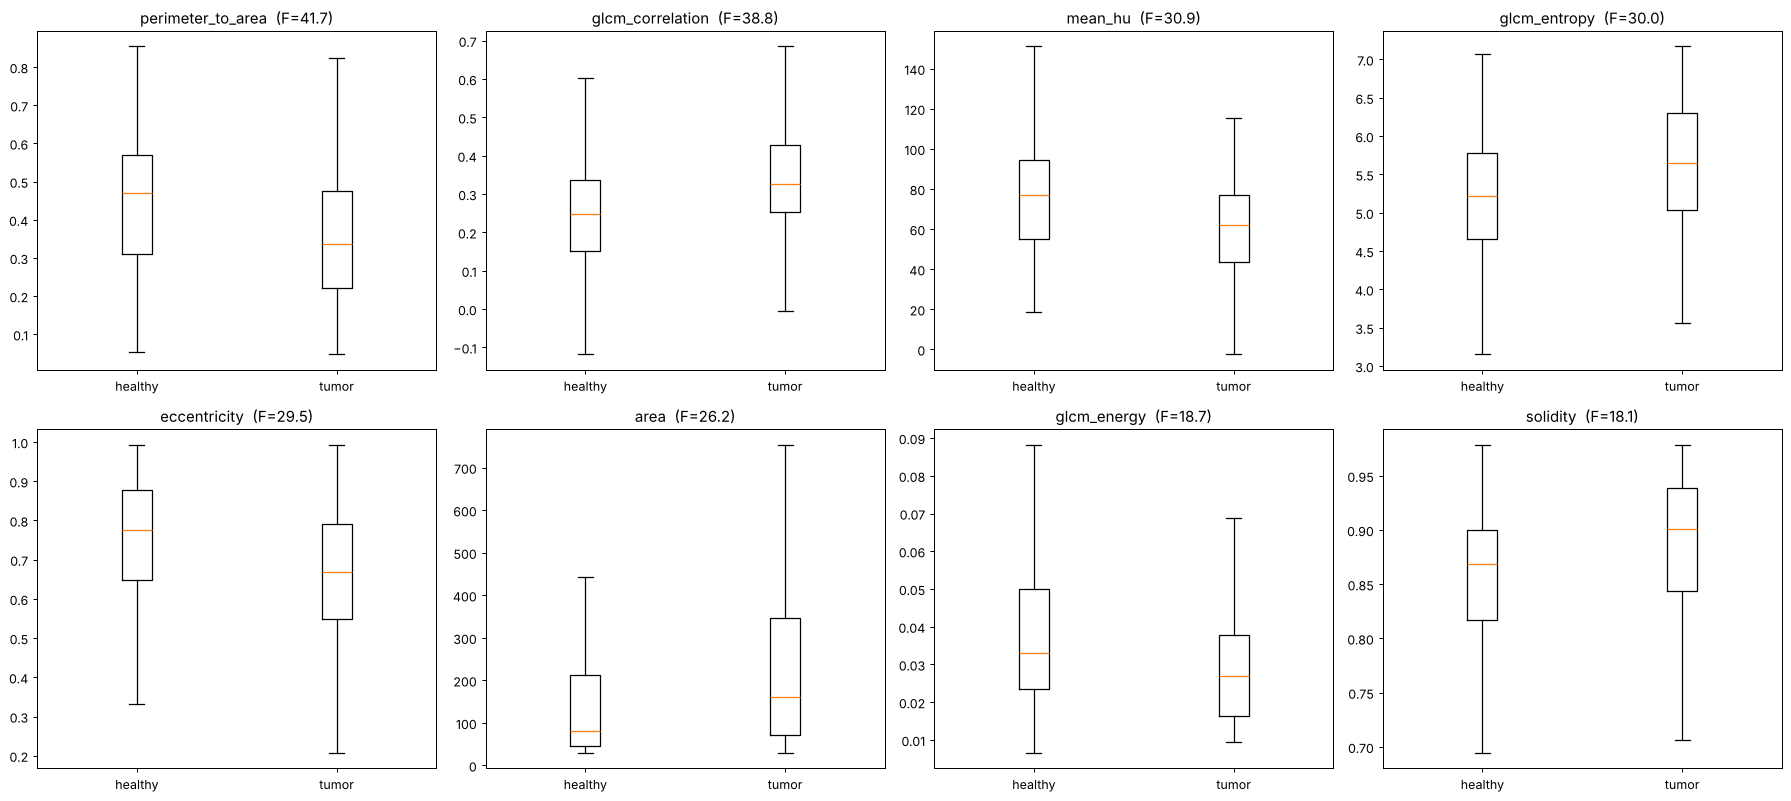

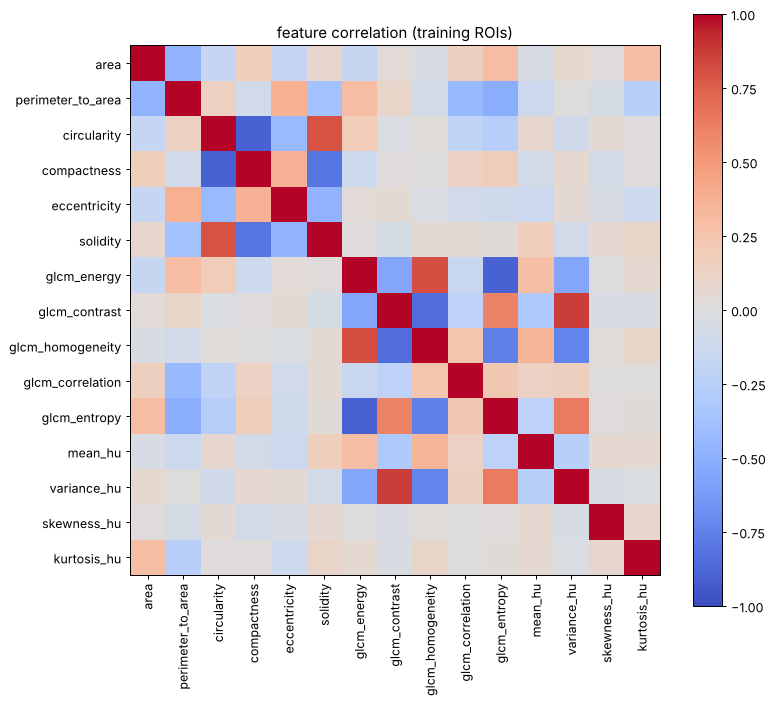

In [8]:
top = list(ft.index[:8])
fig, ax = plt.subplots(2, 4, figsize=(20, 9))
for a, n in zip(ax.ravel(), top):
    j = feat.FEATURE_NAMES.index(n)
    a.boxplot([Xtr[ytr == 0, j], Xtr[ytr == 1, j]], tick_labels=["healthy", "tumor"], showfliers=False)
    a.set_title("%s  (F=%.1f)" % (n, ft.loc[n, "F"]))
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_feature_boxplots.png", dpi=100); plt.show()

Z = (Xtr - Xtr.mean(0)) / (Xtr.std(0) + 1e-12)
corr = np.corrcoef(Z.T)
fig, a = plt.subplots(figsize=(9, 8))
im = a.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); a.set_xticks(range(15)); a.set_yticks(range(15))
a.set_xticklabels(feat.FEATURE_NAMES, rotation=90); a.set_yticklabels(feat.FEATURE_NAMES); plt.colorbar(im); a.set_title("feature correlation (training ROIs)")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_feature_correlation.png", dpi=100); plt.show()

**Findings (feature analysis).**

* The most discriminative features (ANOVA F-test, training ROIs) are **perimeter-to-area** (F = 41.7), **GLCM correlation** (38.8), **mean HU** (30.9), **GLCM entropy** (30.0) and **eccentricity** (29.5), followed by area (26.2), GLCM energy (18.7) and solidity (18.1); all have p < 1e-4. Tumor ROIs have a lower mean HU (61.6 vs 74.7), a higher entropy (5.61 vs 5.18) and higher GLCM correlation (0.34 vs 0.25), that is, they are darker and their texture is more irregular than healthy liver.
* **Circularity (p = 0.995) and compactness (p = 0.16) do not discriminate**, and neither do GLCM contrast (p = 0.69), homogeneity (p = 0.37) and the higher moments of the HU histogram (skewness p = 0.12, kurtosis p = 0.23). The first is by design: the shape-matched controls copy the tumors' outlines.
* **Caution on the size and shape features.** Tumor ROIs and controls have almost the same median area (160 vs 150 px) because controls copy the tumor shape, but the false-positive candidates are much smaller (median 60 px). Area, perimeter-to-area, eccentricity and solidity therefore separate tumors from *candidate blobs*, not from controls; the classifier partly learns that a very small dark blob is a vessel or noise.
* **Redundant features:** glcm_energy and glcm_entropy (r = -0.89), circularity and compactness (r = -0.89), glcm_contrast and variance_hu (r = 0.87), glcm_contrast and glcm_homogeneity (r = -0.84). The 15 features are far from independent, which hurts Naive Bayes-type assumptions but not the SVM or the Random Forest much.

## Task 2: Pattern classification

**Protocol**

1. Patients are split **70 % / 30 %** (done above). The 30 % test patients are used **once**, at the end.
2. On the 70 % training patients, hyper-parameters are chosen with **stratified 5-fold cross-validation**, where all ROIs of a patient stay in the same fold (a patient never appears in both training and validation).
3. Every classifier is a pipeline *z-score scaler -> classifier*; the scaler is fitted on the training part of each fold only.
4. Classifiers: **SVM (RBF kernel)**, **k-NN** and **Random Forest** (`class_weight = "balanced"` where available because healthy ROIs outnumber tumor ROIs).

In [9]:
# the grouped folds: no patient in two folds, tumors in every fold
rows = []
for f, (tr, va) in enumerate(C.grouped_folds(5, SEED).split(Xtr, ytr, gtr), 1):
    assert not (set(gtr[tr]) & set(gtr[va])), "patient leakage between training and validation"
    rows.append(dict(fold=f, train_ROIs=len(tr), val_ROIs=len(va), val_patients=len(set(gtr[va])), val_tumor_ROIs=int(ytr[va].sum())))
print("no patient appears in both the training and the validation part of any fold")
pd.DataFrame(rows).set_index("fold")

no patient appears in both the training and the validation part of any fold


,train_ROIs,val_ROIs,val_patients,val_tumor_ROIs
fold,,,,
1,471,126,5,31
2,481,116,4,31
3,470,127,4,39
4,480,117,4,36
5,486,111,4,30


In [10]:
results = {}
for name in ("svm", "knn", "rf"):
    model, best = C.tune_classifier(name, Xtr, ytr, gtr, SEED)           # 5-fold grouped CV grid search (score: F1 of tumor class)
    folds = C.cross_validate_model(model, Xtr, ytr, gtr, SEED)           # per-fold metrics with the chosen parameters
    model.fit(Xtr, ytr)
    cm, mt, pred = C.evaluate_model(model, Xte, yte)                      # held-out test patients, evaluated once
    results[name] = dict(model=model, best=best, cv=C.summarize_folds(folds), cm=cm, test=mt, pred=pred)
    print(name, "best parameters:", best)

NAMES = {"svm": "SVM (RBF)", "knn": "k-NN", "rf": "Random Forest"}
met_cols = ["accuracy", "sensitivity", "specificity", "precision", "f1"]
cv_tab = pd.DataFrame({NAMES[n]: {k: "%.3f ± %.3f" % results[n]["cv"][k] for k in met_cols} for n in results}).T
te_tab = pd.DataFrame({NAMES[n]: results[n]["test"] for n in results}).T[met_cols].round(3)
print("\n5-fold cross-validation on the training patients (mean ± std over folds)")
display(cv_tab)
print("held-out test patients")
te_tab.to_csv(FIG_DIR + "/p3_test_metrics.csv"); cv_tab.to_csv(FIG_DIR + "/p3_cv_metrics.csv")
te_tab

svm best parameters: {'clf__C': 4, 'clf__gamma': 0.01}
knn best parameters: {'clf__n_neighbors': 9, 'clf__weights': 'distance'}


rf best parameters: {'clf__max_depth': 5, 'clf__min_samples_leaf': 3}

5-fold cross-validation on the training patients (mean ± std over folds)


,accuracy,sensitivity,specificity,precision,f1
SVM (RBF),0.746 ± 0.092,0.690 ± 0.185,0.771 ± 0.170,0.598 ± 0.153,0.606 ± 0.086
k-NN,0.789 ± 0.036,0.479 ± 0.104,0.914 ± 0.083,0.739 ± 0.160,0.557 ± 0.028
Random Forest,0.788 ± 0.051,0.681 ± 0.082,0.832 ± 0.086,0.634 ± 0.107,0.645 ± 0.051


held-out test patients


,accuracy,sensitivity,specificity,precision,f1
SVM (RBF),0.720,0.667,0.739,0.477,0.556
k-NN,0.795,0.397,0.938,0.694,0.505
Random Forest,0.774,0.603,0.835,0.567,0.585


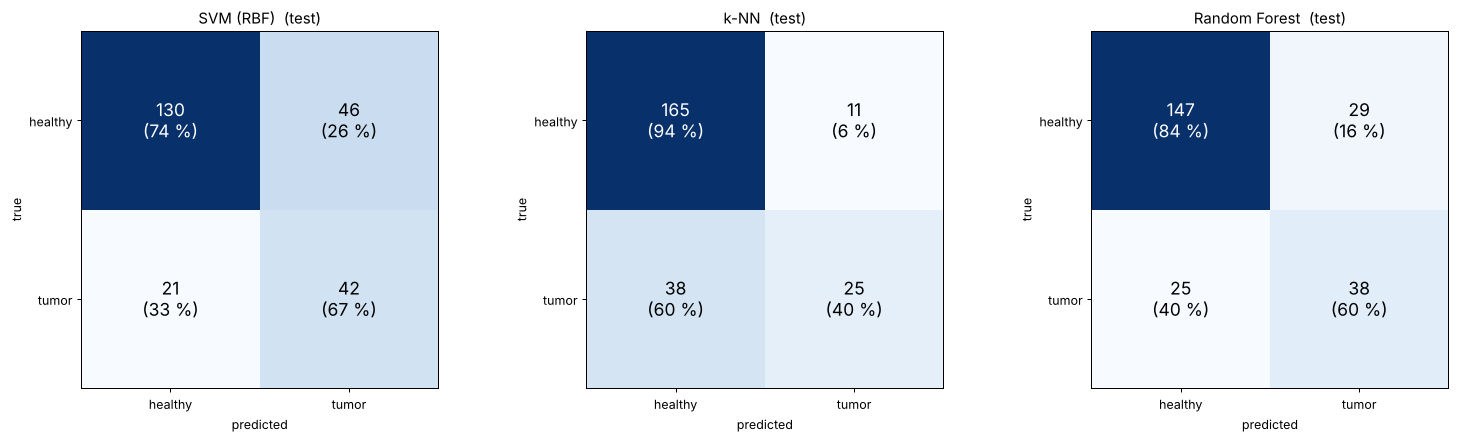

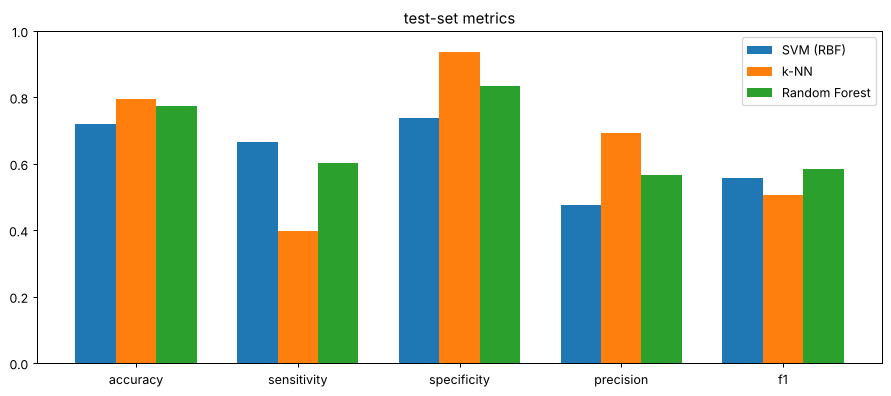

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, n in zip(ax, results):
    cm = results[n]["cm"]; a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, "%d\n(%.0f %%)" % (cm[i, j], 100 * cm[i, j] / cm[i].sum()), ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["healthy", "tumor"]); a.set_yticklabels(["healthy", "tumor"])
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title("%s  (test)" % NAMES[n])
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_confusion_matrices.png", dpi=100); plt.show()

fig, a = plt.subplots(figsize=(10, 4.5)); w = 0.25
for i, n in enumerate(results):
    a.bar(np.arange(5) + i * w, [results[n]["test"][k] for k in met_cols], w, label=NAMES[n])
a.set_xticks(np.arange(5) + w); a.set_xticklabels(met_cols); a.set_ylim(0, 1); a.legend(); a.set_title("test-set metrics")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_metrics_bars.png", dpi=100); plt.show()

selected classifier: Random Forest  (CV F1 0.645 ± 0.051)
test:  {'accuracy': 0.774, 'sensitivity': 0.603, 'specificity': 0.835, 'precision': 0.567, 'f1': 0.585}


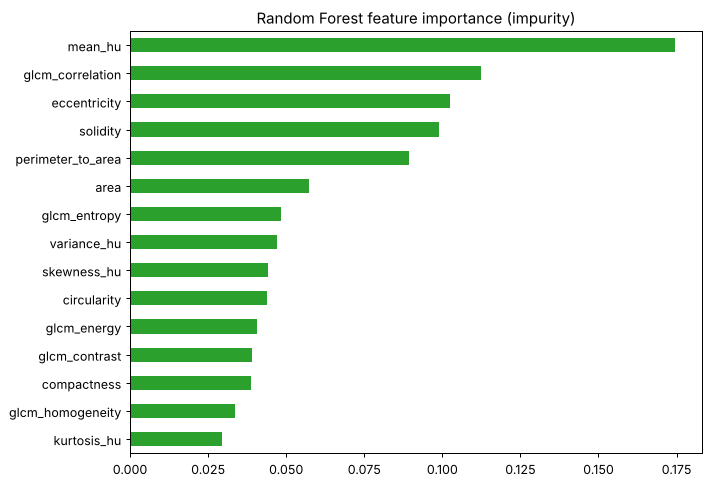

In [12]:
# model choice uses the cross-validation F1 on the TRAINING patients only (never the test set)
best_name = max(results, key=lambda n: results[n]["cv"]["f1"][0])
best = results[best_name]
print("selected classifier: %s  (CV F1 %.3f ± %.3f)" % (NAMES[best_name], *best["cv"]["f1"]))
print("test: ", {k: round(v, 3) for k, v in best["test"].items()})

rf = results["rf"]["model"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=feat.FEATURE_NAMES).sort_values()
fig, a = plt.subplots(figsize=(8, 5.5)); imp.plot.barh(ax=a, color="tab:green"); a.set_title("Random Forest feature importance (impurity)")
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_rf_importance.png", dpi=100); plt.show()

**Findings (classification).**

* **Random Forest** has the highest cross-validated F1 on the training patients (0.645 ± 0.051), so it is the selected model (selection never looked at the test set). Test accuracy 0.774, sensitivity 0.603, specificity 0.835, precision 0.567, F1 0.585.
* **SVM** has the highest tumor sensitivity (0.667 on test) but the lowest precision (0.477): it flags many healthy ROIs. **k-NN** has the highest accuracy (0.795) and specificity (0.938) but misses most tumors (sensitivity 0.397): its high accuracy comes from the majority healthy class, which is why accuracy alone is not a good criterion for this task.
* Cross-validation and test scores agree (for example Random Forest accuracy 0.788 on the folds and 0.774 on the test patients), so there is no sign of over-fitting to the training patients. The folds are noisy though: the SVM's sensitivity varies from fold to fold with a standard deviation of 0.185, because a fold holds only 4-5 patients and about 30-40 tumor ROIs. The test set is also small (9 patients, 63 tumor ROIs), so differences of a few percent between classifiers are not significant.
* The Random Forest relies most on **mean HU** (importance 0.17), **GLCM correlation** (0.11), **eccentricity** (0.10) and **solidity** (0.10), in line with the ANOVA ranking.

## Critical analysis: which ROIs are misclassified?

The error rate is broken down by ROI kind and by tumor size on the test patients, and the misclassified regions are shown. (The ROI crops are rebuilt with the same random seed; the code verifies that they are identical to the ones used above.)

In [13]:
def build_with_crops(pids, seed, margin=25):
    """Same ROIs as C.build_roi_dataset, but also keep a small image crop of each one for display."""
    rng = np.random.default_rng(seed); out = []
    for pid, sl, hu_i, m_i in util.iter_slices(DATA_DIR, pids):
        if (m_i >= 1).sum() < C.MIN_LIVER_PX: continue
        g = util.hu_to_gray(hu_i)
        for roi, lab, kind in C.slice_rois(g, m_i, rng):
            ys, xs = np.where(roi); y0, x0 = max(ys.min() - margin, 0), max(xs.min() - margin, 0)
            out.append(dict(pid=pid, slice=sl, kind=kind, y=lab, crop=g[y0:ys.max() + margin, x0:xs.max() + margin], mcrop=roi[y0:ys.max() + margin, x0:xs.max() + margin]))
    return out
crops = build_with_crops(test_p, SEED)
assert [(c["pid"], c["slice"], c["kind"]) for c in crops] == mte, "ROI order differs from the evaluated dataset"
assert np.array_equal(np.array([c["mcrop"].sum() for c in crops]), Xte[:, 0]), "ROI areas differ from the evaluated dataset"
print("ROI crops identical to the evaluated test ROIs:", len(crops))

pred = best["pred"]
err = pd.DataFrame({"kind": [c["kind"] for c in crops], "true": yte, "pred": pred, "area": Xte[:, 0]})
err["wrong"] = err.true != err.pred
by_kind = err.groupby("kind").agg(ROIs=("wrong", "size"), misclassified=("wrong", "sum"), error_rate=("wrong", "mean")).round(3)
print("error rate by ROI kind (%s, test patients)" % NAMES[best_name]); display(by_kind)
tum = err[err.true == 1].copy(); tum["size"] = pd.cut(tum.area, [0, 100, 300, 1e9], labels=["small (<100 px)", "medium (100-300 px)", "large (>300 px)"])
print("tumor ROIs: sensitivity by tumor size")
tum.groupby("size", observed=True).agg(tumor_ROIs=("pred", "size"), detected=("pred", "sum"), sensitivity=("pred", "mean")).round(3)

ROI crops identical to the evaluated test ROIs: 239
error rate by ROI kind (Random Forest, test patients)


,ROIs,misclassified,error_rate
kind,,,
control,62,7,0.113
fp_candidate,114,22,0.193
tumor,63,25,0.397


tumor ROIs: sensitivity by tumor size


,tumor_ROIs,detected,sensitivity
size,,,
small (<100 px),25,4,0.160
medium (100-300 px),9,7,0.778
large (>300 px),29,27,0.931


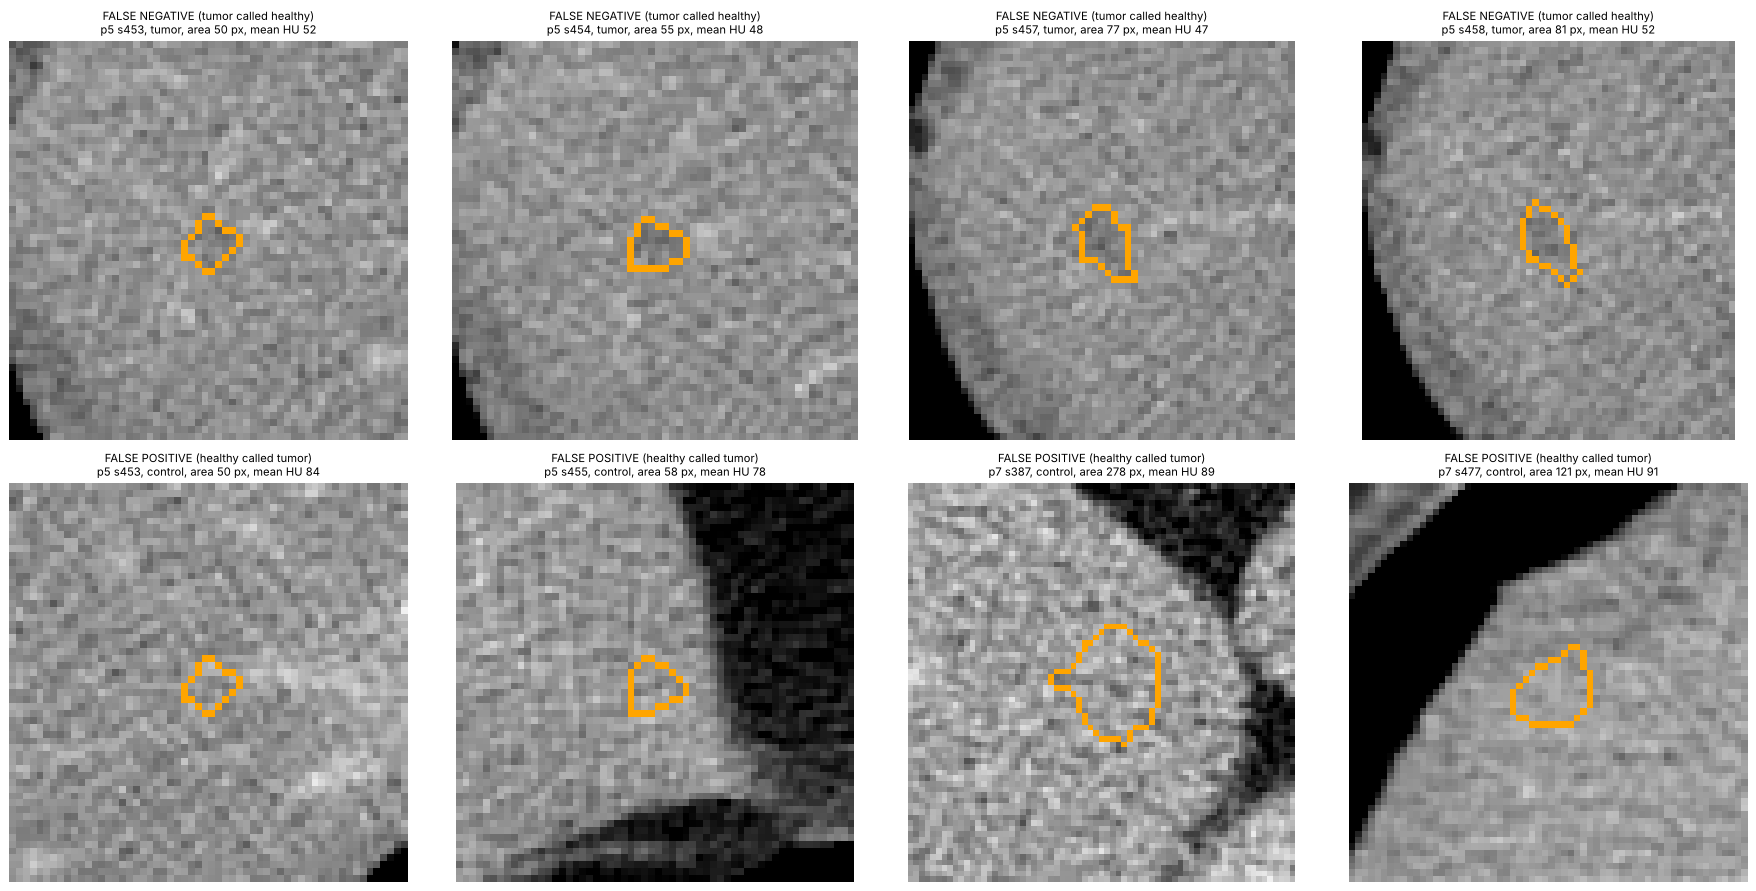

In [14]:
fn = [i for i in range(len(crops)) if yte[i] == 1 and pred[i] == 0][:4]
fp = [i for i in range(len(crops)) if yte[i] == 0 and pred[i] == 1][:4]
fig, ax = plt.subplots(2, 4, figsize=(20, 10))
for row, (ids, title) in enumerate([(fn, "FALSE NEGATIVE (tumor called healthy)"), (fp, "FALSE POSITIVE (healthy called tumor)")]):
    for col in range(4):
        a = ax[row, col]; a.axis("off")
        if col >= len(ids): continue
        c = crops[ids[col]]; img = cv2.cvtColor(c["crop"], cv2.COLOR_GRAY2RGB)
        cs, _ = cv2.findContours(c["mcrop"].astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE); cv2.drawContours(img, cs, -1, (255, 165, 0), 1)
        a.imshow(img, interpolation="nearest"); a.set_title("%s\np%d s%d, %s, area %d px, mean HU %.0f" % (title, c["pid"], c["slice"], c["kind"], Xte[ids[col], 0], Xte[ids[col], feat.FEATURE_NAMES.index("mean_hu")]), fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_misclassified.png", dpi=100); plt.show()

**Findings (error analysis, Random Forest, test patients).**

* **Small tumors are the problem.** Sensitivity is 16 % (4 of 25) for tumors under 100 px, 78 % (7 of 9) for 100-300 px, and 93 % (27 of 29) above 300 px. The 25 small tumors make up 40 % of the test tumors but 21 of the 25 missed ones (84 %).
* The false negatives shown above are small (50-81 px) and clearly darker than the liver (mean 47-52 HU, against 78-91 HU for the false positives below), but they sit in noisy parenchyma. With so few pixels the GLCM and the HU statistics are noisy estimates, and a small dark blob looks like the false-positive candidates (vessels, noise) that the classifier was trained to reject.
* **False alarms:** 19 % of the false-positive candidates (22 of 114) and 11 % of the shape-matched controls (7 of 62) are called tumor. The false positives shown are small regions, some in ordinary parenchyma and some next to the liver boundary, where partial volume with the lung or fat probably produces a darker rim.
* Hence the limit of this feature set is not the classifier but the **information content of a handful of noisy pixels**. Possible improvements: a minimum-size rule with a different decision for small lesions, multi-slice (3D) features, features from a ring of surrounding tissue (local contrast), and more training patients (extraction of more patients, see the project notes).

## End-to-end pipeline on raw test slices

The classifier above was evaluated on ROIs cut from the ground-truth liver. The real pipeline has no ground truth, so here it is run from the **raw HU slice** of every test patient:

raw slice -> window + bilateral filter (Phase 1) -> liver mask, Strategy A (Phase 2) -> dark candidate blobs inside the *predicted* liver (relaxed lesion detector) -> 15 features per blob -> classifier -> blobs predicted *tumor* form the final lesion mask.

Two things are measured: the **slice-level** decision (does this slice contain a tumor?) and the **pixel-level** lesion Dice, compared with the Phase 2 lesion detector alone (which has no classification step).

In [15]:
model = best["model"]

def pipeline_slice(hu_i):
    o = S.segment_slice(hu_i, "A")                                         # Phase 1 + Phase 2
    gw = util.hu_to_gray(hu_i)
    cand = S.segment_lesion(o["gray"], o["organ"], k=1.5, min_drop=8, min_area=C.MIN_ROI_AREA, min_solidity=0.0)
    comps = C.split_components(cand)
    calls = [int(model.predict(feat.extract_features(hu_i, gw, c)[None])[0]) for c in comps] if comps else []
    tumor = np.zeros(hu_i.shape, bool)
    for c, p in zip(comps, calls):
        if p == 1: tumor |= c
    return o, comps, calls, tumor

rows = []
for pid, sl, hu_i, m_i in util.iter_slices(DATA_DIR, test_p):
    if (m_i >= 1).sum() < C.MIN_LIVER_PX: continue
    o, comps, calls, tumor = pipeline_slice(hu_i)
    gt_t = m_i == 2; has = int(gt_t.sum() >= 50)
    rows.append(dict(patient=pid, slice=sl, has_tumor=has, pred_tumor=int(tumor.any()), phase2_alarm=int(o["lesion"].any()), n_candidates=len(comps),
                     dice_final=M.dice_score(tumor, gt_t), dice_phase2=M.dice_score(o["lesion"], gt_t)))
e2e = pd.DataFrame(rows)
sl_metrics = M.classification_metrics(e2e.has_tumor.values, e2e.pred_tumor.values)
print("test slices:", len(e2e), "| with tumor:", int(e2e.has_tumor.sum()), "| tumor-free:", int((1 - e2e.has_tumor).sum()))
print("SLICE-LEVEL decision (tumor present?):", {k: round(v, 3) for k, v in sl_metrics.items()})
print("confusion [[TN, FP], [FN, TP]]:", M.confusion_matrix_2x2(e2e.has_tumor.values, e2e.pred_tumor.values).tolist())
t, f = e2e[e2e.has_tumor == 1], e2e[e2e.has_tumor == 0]
print("lesion Dice on tumor slices: Phase 2 detector alone %.3f  ->  with classifier %.3f" % (t.dice_phase2.mean(), t.dice_final.mean()))
print("false-alarm rate on tumor-free slices: Phase 2 detector alone %.0f %%  ->  with classifier %.0f %%" % (100 * f.phase2_alarm.mean(), 100 * f.pred_tumor.mean()))

test slices: 89 | with tumor: 53 | tumor-free: 36
SLICE-LEVEL decision (tumor present?): {'accuracy': 0.629, 'sensitivity': 0.642, 'specificity': 0.611, 'precision': 0.708, 'f1': 0.673}
confusion [[TN, FP], [FN, TP]]: [[22, 14], [19, 34]]
lesion Dice on tumor slices: Phase 2 detector alone 0.269  ->  with classifier 0.295
false-alarm rate on tumor-free slices: Phase 2 detector alone 50 %  ->  with classifier 39 %


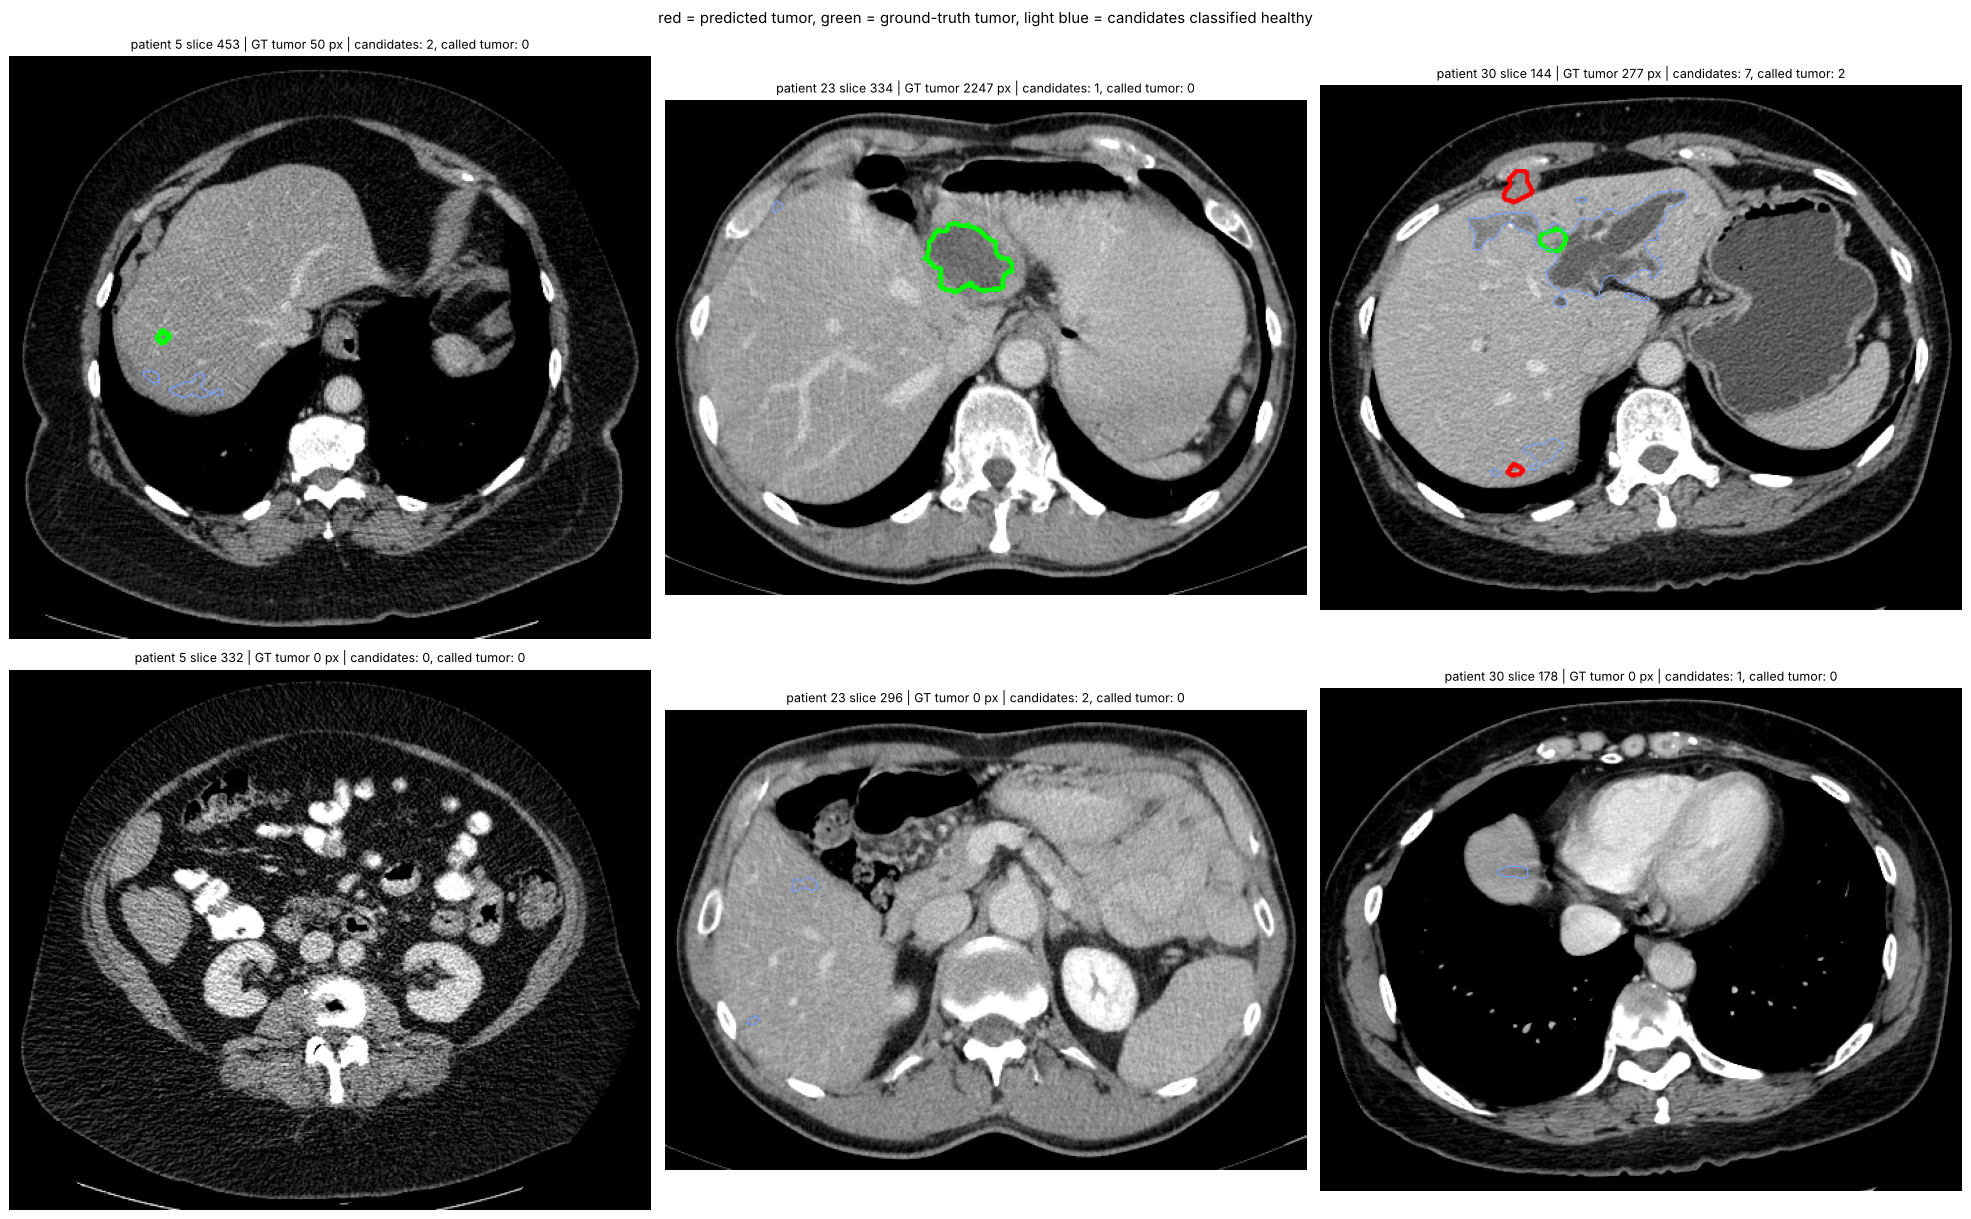

In [16]:
# six test slices chosen at evenly spaced positions: three with a tumor, three tumor-free (no cherry-picking)
tr_rows = e2e[e2e.has_tumor == 1].reset_index(drop=True); fr_rows = e2e[e2e.has_tumor == 0].reset_index(drop=True)
sel = [tr_rows.iloc[i] for i in np.linspace(0, len(tr_rows) - 1, 3).astype(int)] + [fr_rows.iloc[i] for i in np.linspace(0, len(fr_rows) - 1, 3).astype(int)]
shown = []
for r in sel:
    hu_p, m_p, ix = util.load_patient(DATA_DIR, int(r.patient)); k = list(ix).index(int(r.slice))
    o, comps, calls, tumor = pipeline_slice(hu_p[k])
    shown.append((hu_p[k], m_p[k], o, comps, calls, tumor, int(r.patient), int(r.slice)))

fig, ax = plt.subplots(2, 3, figsize=(22, 14))
for a, (hu_i, m_i, o, comps, calls, tumor, pid, sl) in zip(ax.ravel(), shown):
    g0 = util.hu_to_gray(hu_i); img = cv2.cvtColor(g0, cv2.COLOR_GRAY2RGB)
    for msk, col, th in [(m_i == 2, (0, 255, 0), 2), (tumor, (255, 0, 0), 2)]:
        cs, _ = cv2.findContours(msk.astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE); cv2.drawContours(img, cs, -1, col, th)
    for c, p in zip(comps, calls):
        if p == 0:
            cs, _ = cv2.findContours(c.astype(np.uint8), cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE); cv2.drawContours(img, cs, -1, (120, 160, 255), 1)
    a.imshow(crop_to_body(img, o["body"])); a.axis("off")
    a.set_title("patient %d slice %d | GT tumor %d px | candidates: %d, called tumor: %d" % (pid, sl, (m_i == 2).sum(), len(comps), sum(calls)), fontsize=10)
fig.suptitle("red = predicted tumor, green = ground-truth tumor, light blue = candidates classified healthy", y=0.99)
fig.tight_layout(); fig.savefig(FIG_DIR + "/p3_end_to_end.png", dpi=60); plt.show()

In [17]:
# save the selected classifier (trained on the training patients only) for the GUI prototype
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": best["model"], "name": best_name, "features": feat.FEATURE_NAMES}, "../models/liver_classifier.joblib")
print("saved ../models/liver_classifier.joblib")

saved ../models/liver_classifier.joblib


## Summary of Phase 3 and of the whole pipeline

* **ROI classification (healthy vs tumor), held-out test patients:** Random Forest (selected by cross-validation) reaches accuracy 0.774, sensitivity 0.603, specificity 0.835 and F1 0.585. SVM and k-NN trade sensitivity against specificity differently (SVM 0.667 / 0.739, k-NN 0.397 / 0.938).
* **End-to-end on raw test slices** (no ground truth used at any stage): the *slice-level* decision "does this slice contain a tumor?" has accuracy 0.629, sensitivity 0.642, specificity 0.611 and F1 0.673; the classification step lowers the false-alarm rate on tumor-free slices from 50 % (Phase 2 detector alone) to 39 %, and lifts the lesion Dice slightly, from 0.269 to 0.295.
* **Why end-to-end is worse than ROI-level:** errors accumulate. The liver mask can select the wrong organ (heart at the dome of the liver, Phase 2), the candidates are produced by a detector that misses faint lesions, and the classifier, trained on candidates from the *ground-truth* liver, sees a slightly different distribution of candidates in the *predicted* liver.
* **Limitations:** 30 patients (21 for training); a single random patient split; healthy ROIs are shape-matched copies and detector candidates, not a natural class; no tuning on the test set. Extracting more patients (up to about 60) and repeating the patient split several times would give tighter estimates.
* The selected classifier is saved as `../models/liver_classifier.joblib` for the GUI prototype.